### Importing libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### getting dataset

In [2]:
df=pd.read_csv('../dataset/olist_order_payments_dataset.csv')
df.head(2)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39


In [3]:
df.shape

(103886, 5)

In [4]:
df.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

### Insights
1) we have order id to link table.
2) payment_sequential as no. of methods used for payment
3) payment_type method of payment
4) payment_installments number of installment.
5) payment_value id order value.

In [13]:
## avg payment methods
x1=df.groupby('order_id')['payment_sequential'].count().reset_index()
x1=x1.sort_values(by='payment_sequential',ascending=False)
print(x1['payment_sequential'].mean())

1.0447103781174578


In [14]:
## payment methods
df['payment_type'].nunique()

5

In [20]:
# avg payment installments 
x2=df.groupby('order_id')['payment_installments'].sum().reset_index()
x2=x2.sort_values(by='payment_installments',ascending=False)
x2['payment_installments'].mean()

np.float64(2.853348863176944)

In [21]:
# avg order price
x3=df.groupby('order_id')['payment_value'].sum().reset_index()
x3=x3.sort_values(by='payment_value',ascending=False)
x3['payment_value'].mean()

np.float64(160.9902666934835)

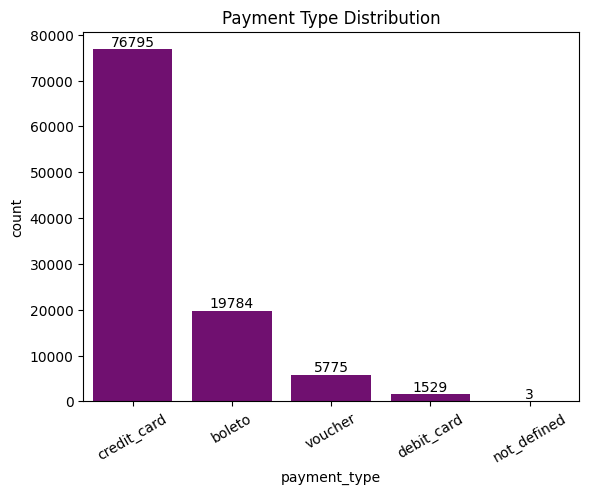

In [26]:
ax=sns.countplot(data=df, x='payment_type', color='purple')
ax.bar_label(ax.containers[0])
plt.title("Payment Type Distribution")
plt.xticks(rotation=30)
plt.show()


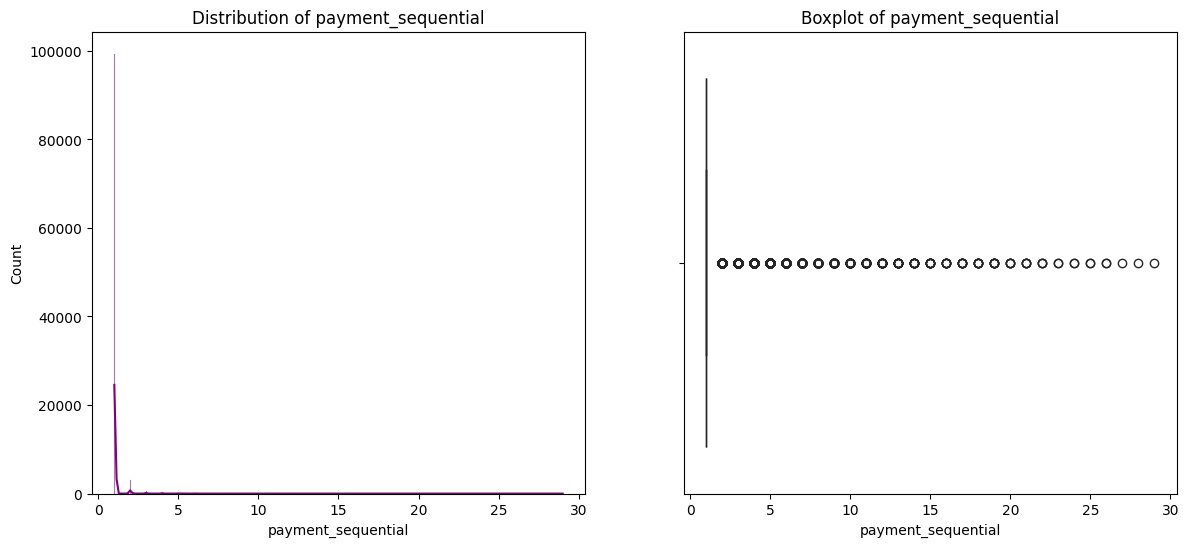

In [32]:
fig, axes = plt.subplots(1,2, figsize=(14,6))

sns.histplot(df['payment_sequential'],kde=True, color='purple', ax=axes[0])
axes[0].set_title("Distribution of payment_sequential")

sns.boxplot(x=df['payment_sequential'], color='purple', ax=axes[1])
axes[1].set_title("Boxplot of payment_sequential")

plt.show()


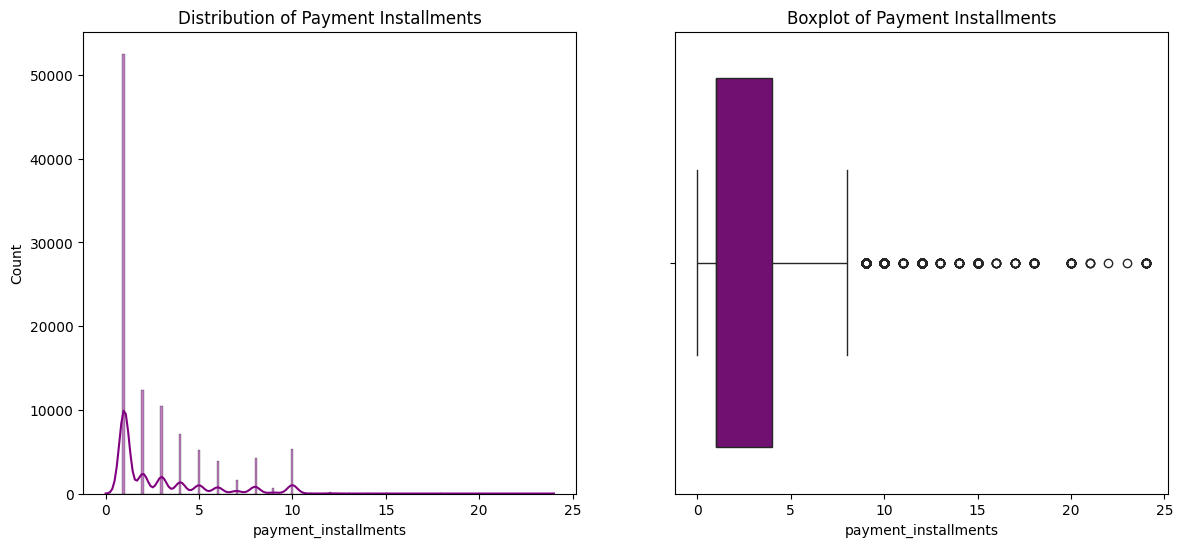

In [28]:
fig, axes = plt.subplots(1,2, figsize=(14,6))

sns.histplot(df['payment_installments'], kde=True, color='purple', ax=axes[0])
axes[0].set_title("Distribution of Payment Installments")

sns.boxplot(x=df['payment_installments'], color='purpale', ax=axes[1])
axes[1].set_title("Boxplot of Payment Installments")

plt.show()

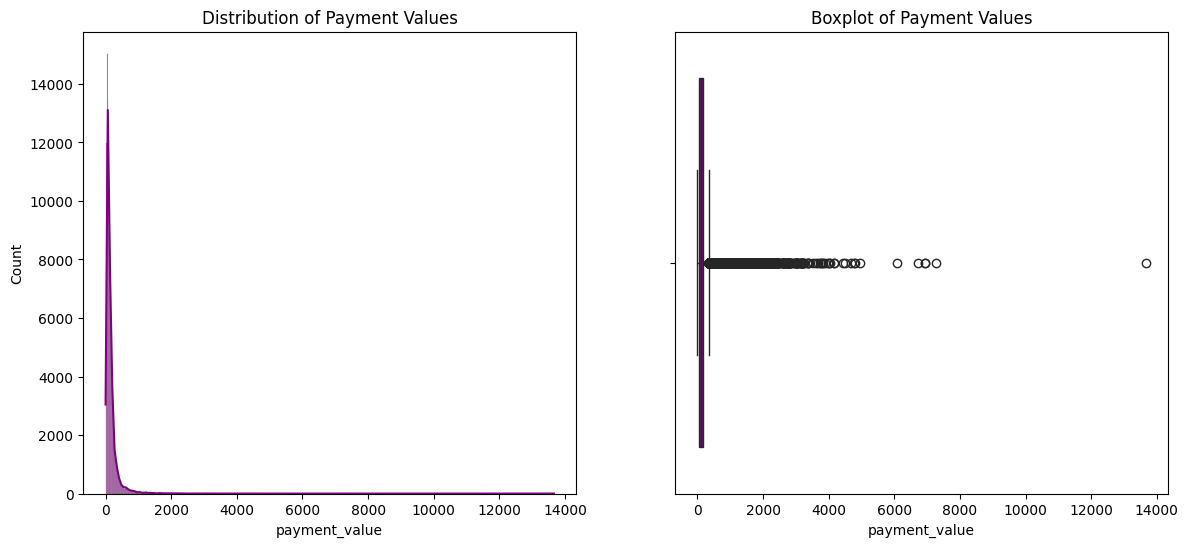

In [31]:
fig, axes = plt.subplots(1,2, figsize=(14,6))

sns.histplot(df['payment_value'], kde=True, color='purple', ax=axes[0])
axes[0].set_title("Distribution of Payment Values")

sns.boxplot(x=df['payment_value'], color='purple', ax=axes[1])
axes[1].set_title("Boxplot of Payment Values")

plt.show()


In [56]:
x4=df.groupby('payment_type')['payment_value'].sum().reset_index()
x4=x4.sort_values(by='payment_value',ascending=False)
x4.columns=['Payment Method','payment value']
x4

,Payment Method,payment value
1,credit_card,12542084.19
0,boleto,2869361.27
4,voucher,379436.87
2,debit_card,217989.79
3,not_defined,0.00


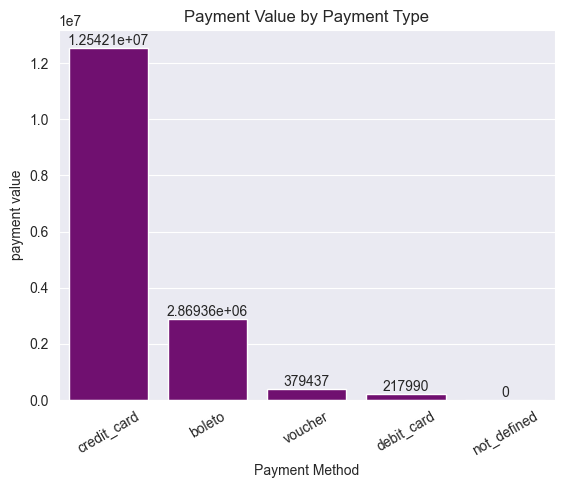

In [57]:
ax=sns.barplot(data=x4, x='Payment Method', y='payment value', color='purple',errorbar=('ci', 0))
ax.bar_label(ax.containers[0])
plt.title("Payment Value by Payment Type")
plt.xticks(rotation=30)
plt.show()


In [59]:
x5=df.groupby('payment_type')['payment_installments'].mean().reset_index()
x5=x5.sort_values(by='payment_installments',ascending=False)
x5.columns=['Payment Method','payment installments']
x5

,Payment Method,payment installments
1,credit_card,3.507155
0,boleto,1.000000
2,debit_card,1.000000
3,not_defined,1.000000
4,voucher,1.000000


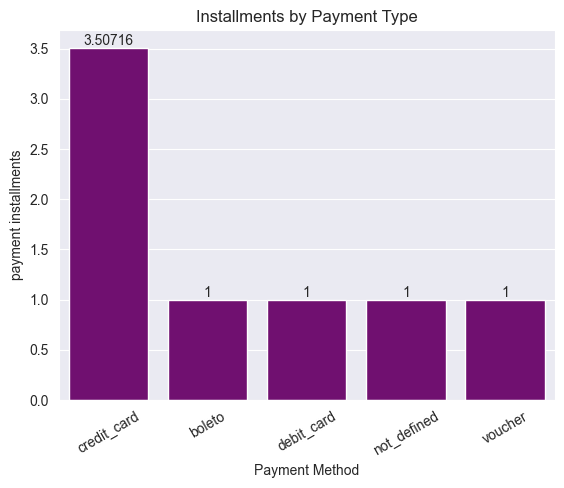

In [61]:
ax=sns.barplot(data=x5, x='Payment Method', y='payment installments', color='purple',errorbar=('ci', 0))
ax.bar_label(ax.containers[0])
plt.title("Installments by Payment Type")
plt.xticks(rotation=30)
plt.show()


In [63]:
x6=df.groupby('payment_type')['payment_value'].mean().reset_index()
x6=x6.sort_values(by='payment_value',ascending=False)
x6.columns=['Payment Method','payment value']
x6

,Payment Method,payment value
1,credit_card,163.319021
0,boleto,145.034435
2,debit_card,142.570170
4,voucher,65.703354
3,not_defined,0.000000


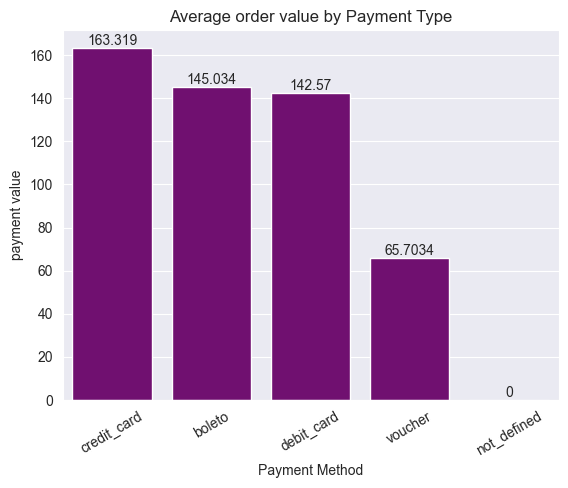

In [67]:
ax=sns.barplot(data=x6, x='Payment Method', y='payment value', color='purple')
ax.bar_label(ax.containers[0])
plt.title("Average order value by Payment Type")
plt.xticks(rotation=30)
plt.show()


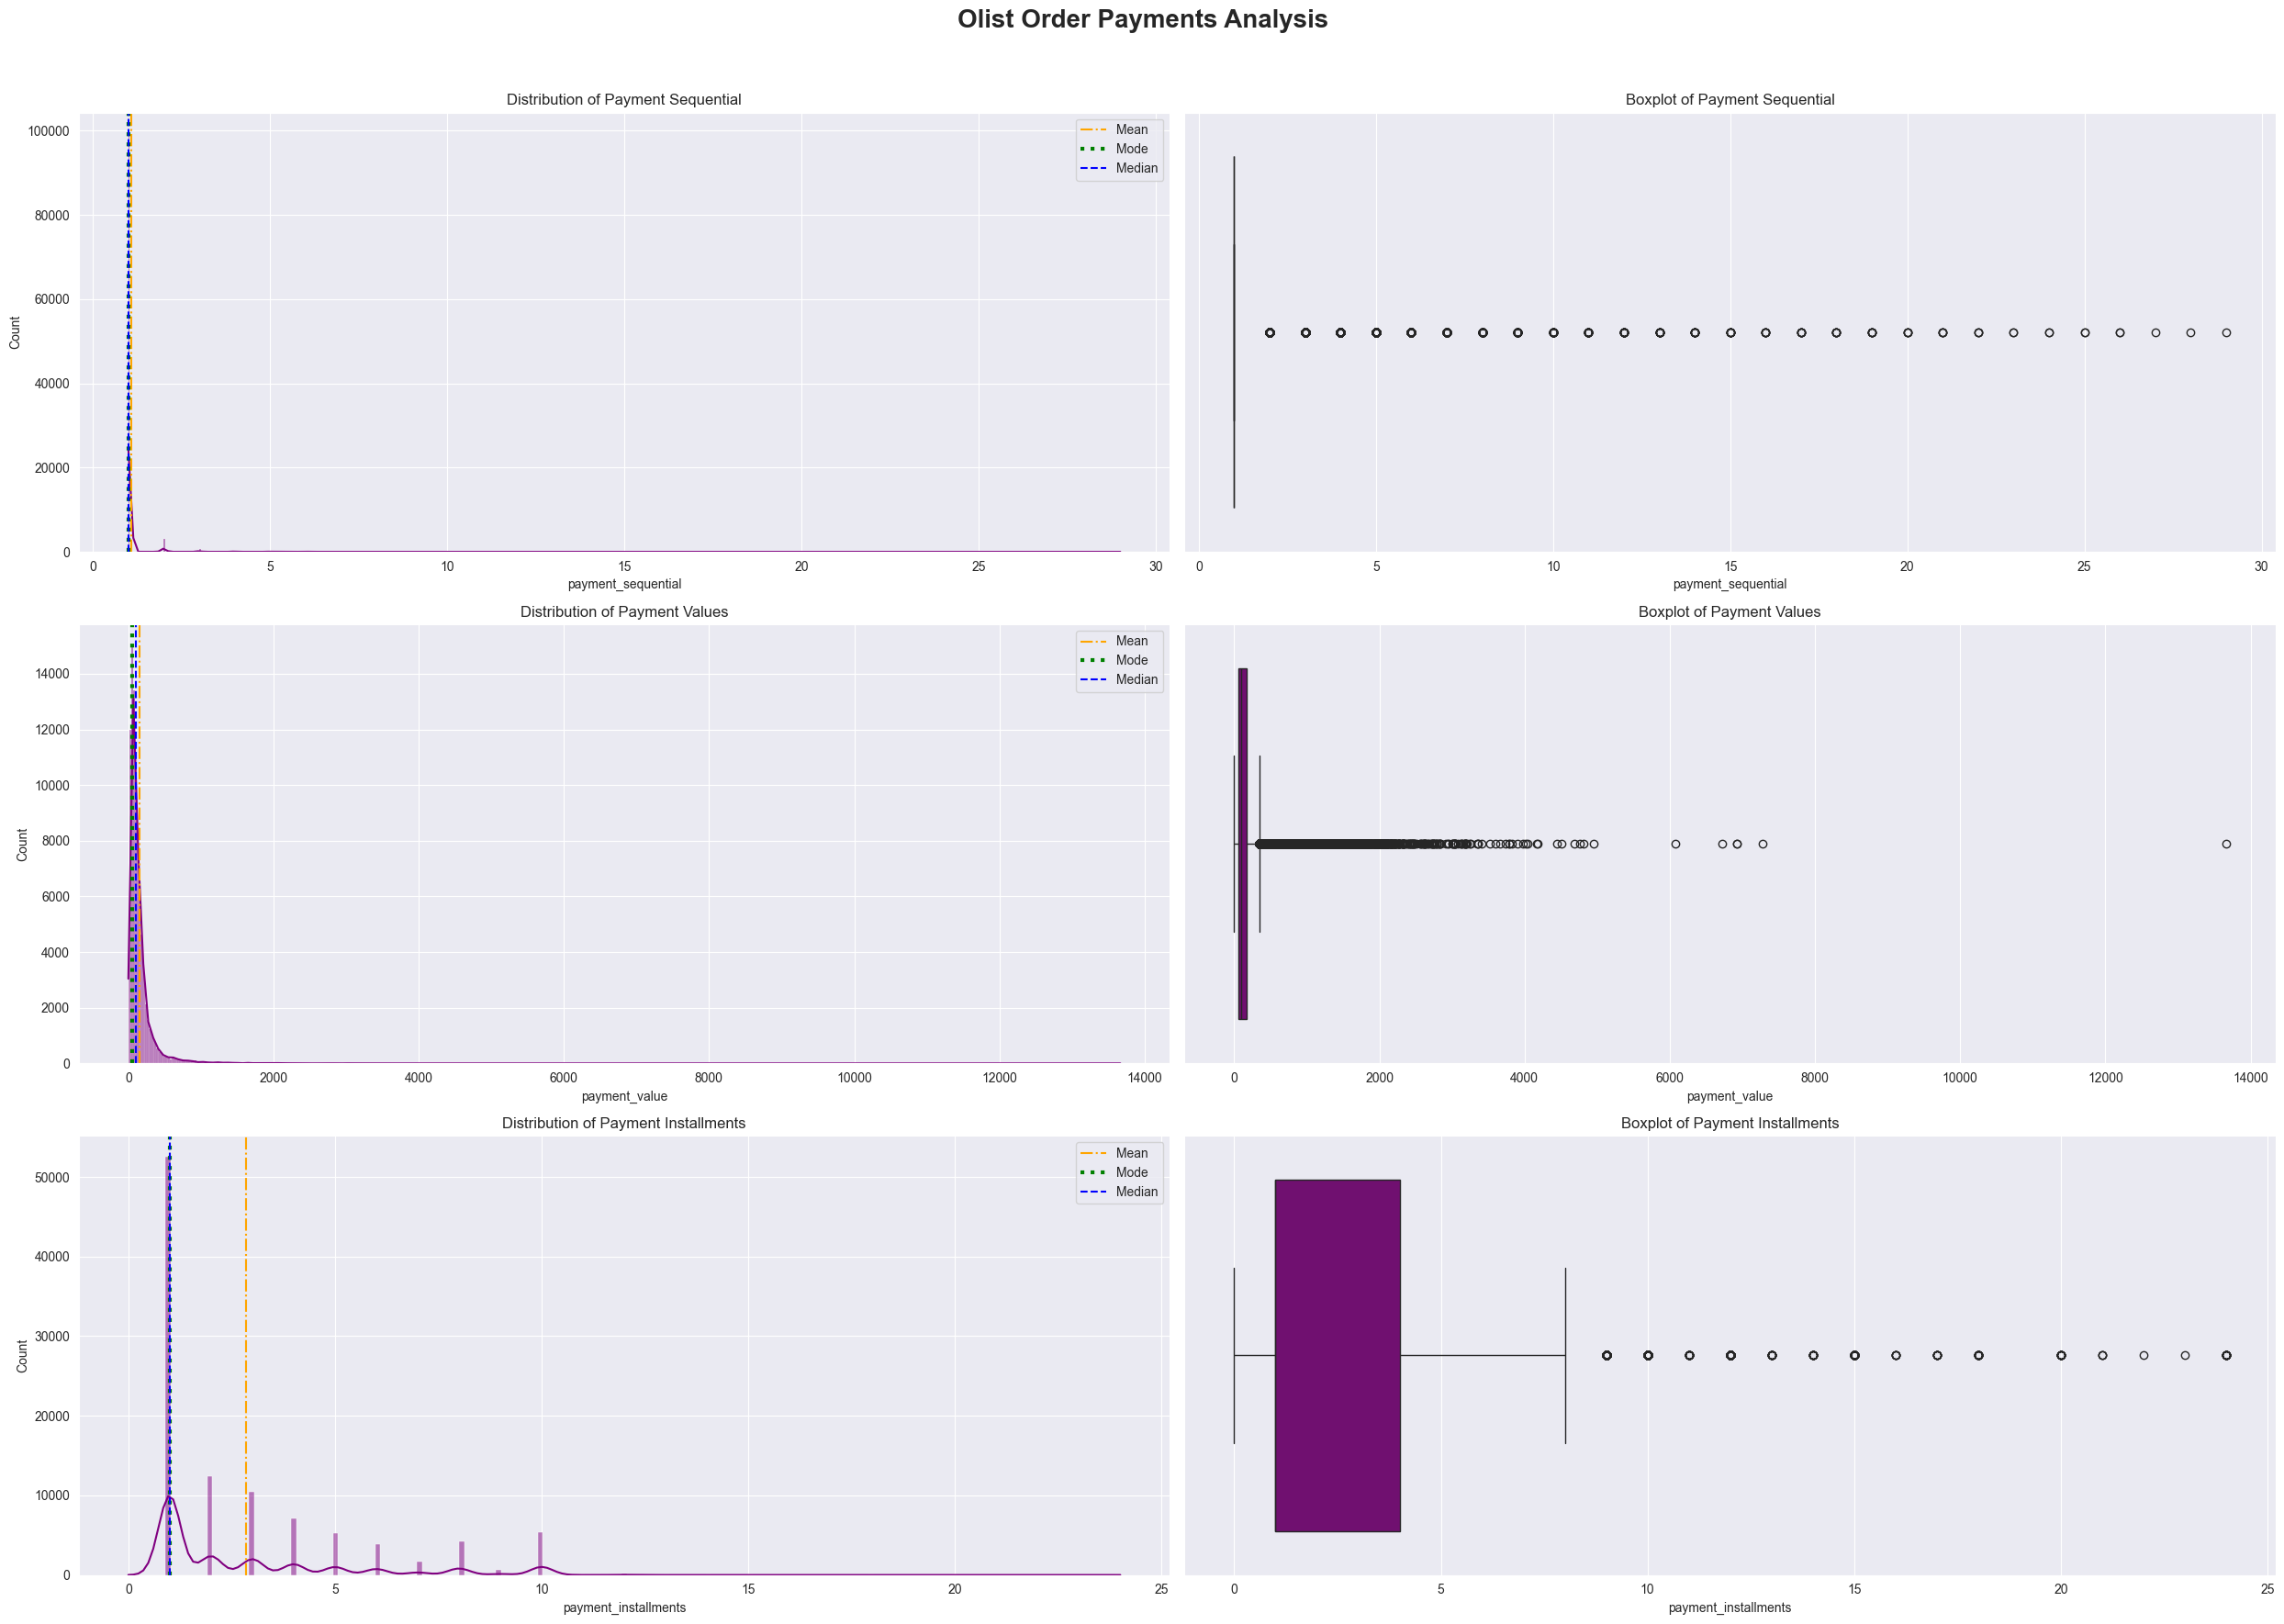

In [51]:
sns.set_style('darkgrid')
fig, axes = plt.subplots(3, 2, figsize=(25,18))

sns.histplot(df['payment_sequential'], kde=True, color='purple', ax=axes[0,0])
axes[0,0].set_title("Distribution of Payment Sequential")
axes[0,0].axvline(df['payment_sequential'].mean(), label='Mean', linestyle='-.', color='orange')
axes[0,0].axvline(df['payment_sequential'].mode()[0], label='Mode', linestyle=':', color='green', linewidth=3)
axes[0,0].axvline(df['payment_sequential'].median(), label='Median', linestyle='--', color='blue')
axes[0,0].legend()

sns.boxplot(x=df['payment_sequential'], color='purple', ax=axes[0,1])
axes[0,1].set_title("Boxplot of Payment Sequential")


sns.histplot(df['payment_value'], kde=True, color='purple', ax=axes[1,0])
axes[1,0].set_title("Distribution of Payment Values")
axes[1,0].axvline(df['payment_value'].mean(), label='Mean', linestyle='-.', color='orange')
axes[1,0].axvline(df['payment_value'].mode()[0], label='Mode', linestyle=':', color='green', linewidth=3)
axes[1,0].axvline(df['payment_value'].median(), label='Median', linestyle='--', color='blue')
axes[1,0].legend()

sns.boxplot(x=df['payment_value'], color='purple', ax=axes[1,1])
axes[1,1].set_title("Boxplot of Payment Values")


sns.histplot(df['payment_installments'], kde=True, color='purple', ax=axes[2,0])
axes[2,0].set_title("Distribution of Payment Installments")
axes[2,0].axvline(df['payment_installments'].mean(), label='Mean', linestyle='-.', color='orange')
axes[2,0].axvline(df['payment_installments'].mode()[0], label='Mode', linestyle=':', color='green', linewidth=3)
axes[2,0].axvline(df['payment_installments'].median(), label='Median', linestyle='--', color='blue')
axes[2,0].legend()

sns.boxplot(x=df['payment_installments'], color='purple', ax=axes[2,1])
axes[2,1].set_title("Boxplot of Payment Installments")

plt.suptitle("Olist Order Payments Analysis", fontsize=20, fontweight='bold')
plt.tight_layout(rect=[0,0,1,0.96])
plt.savefig('Order_payment_histplot.png', dpi=500, bbox_inches="tight")
plt.show()


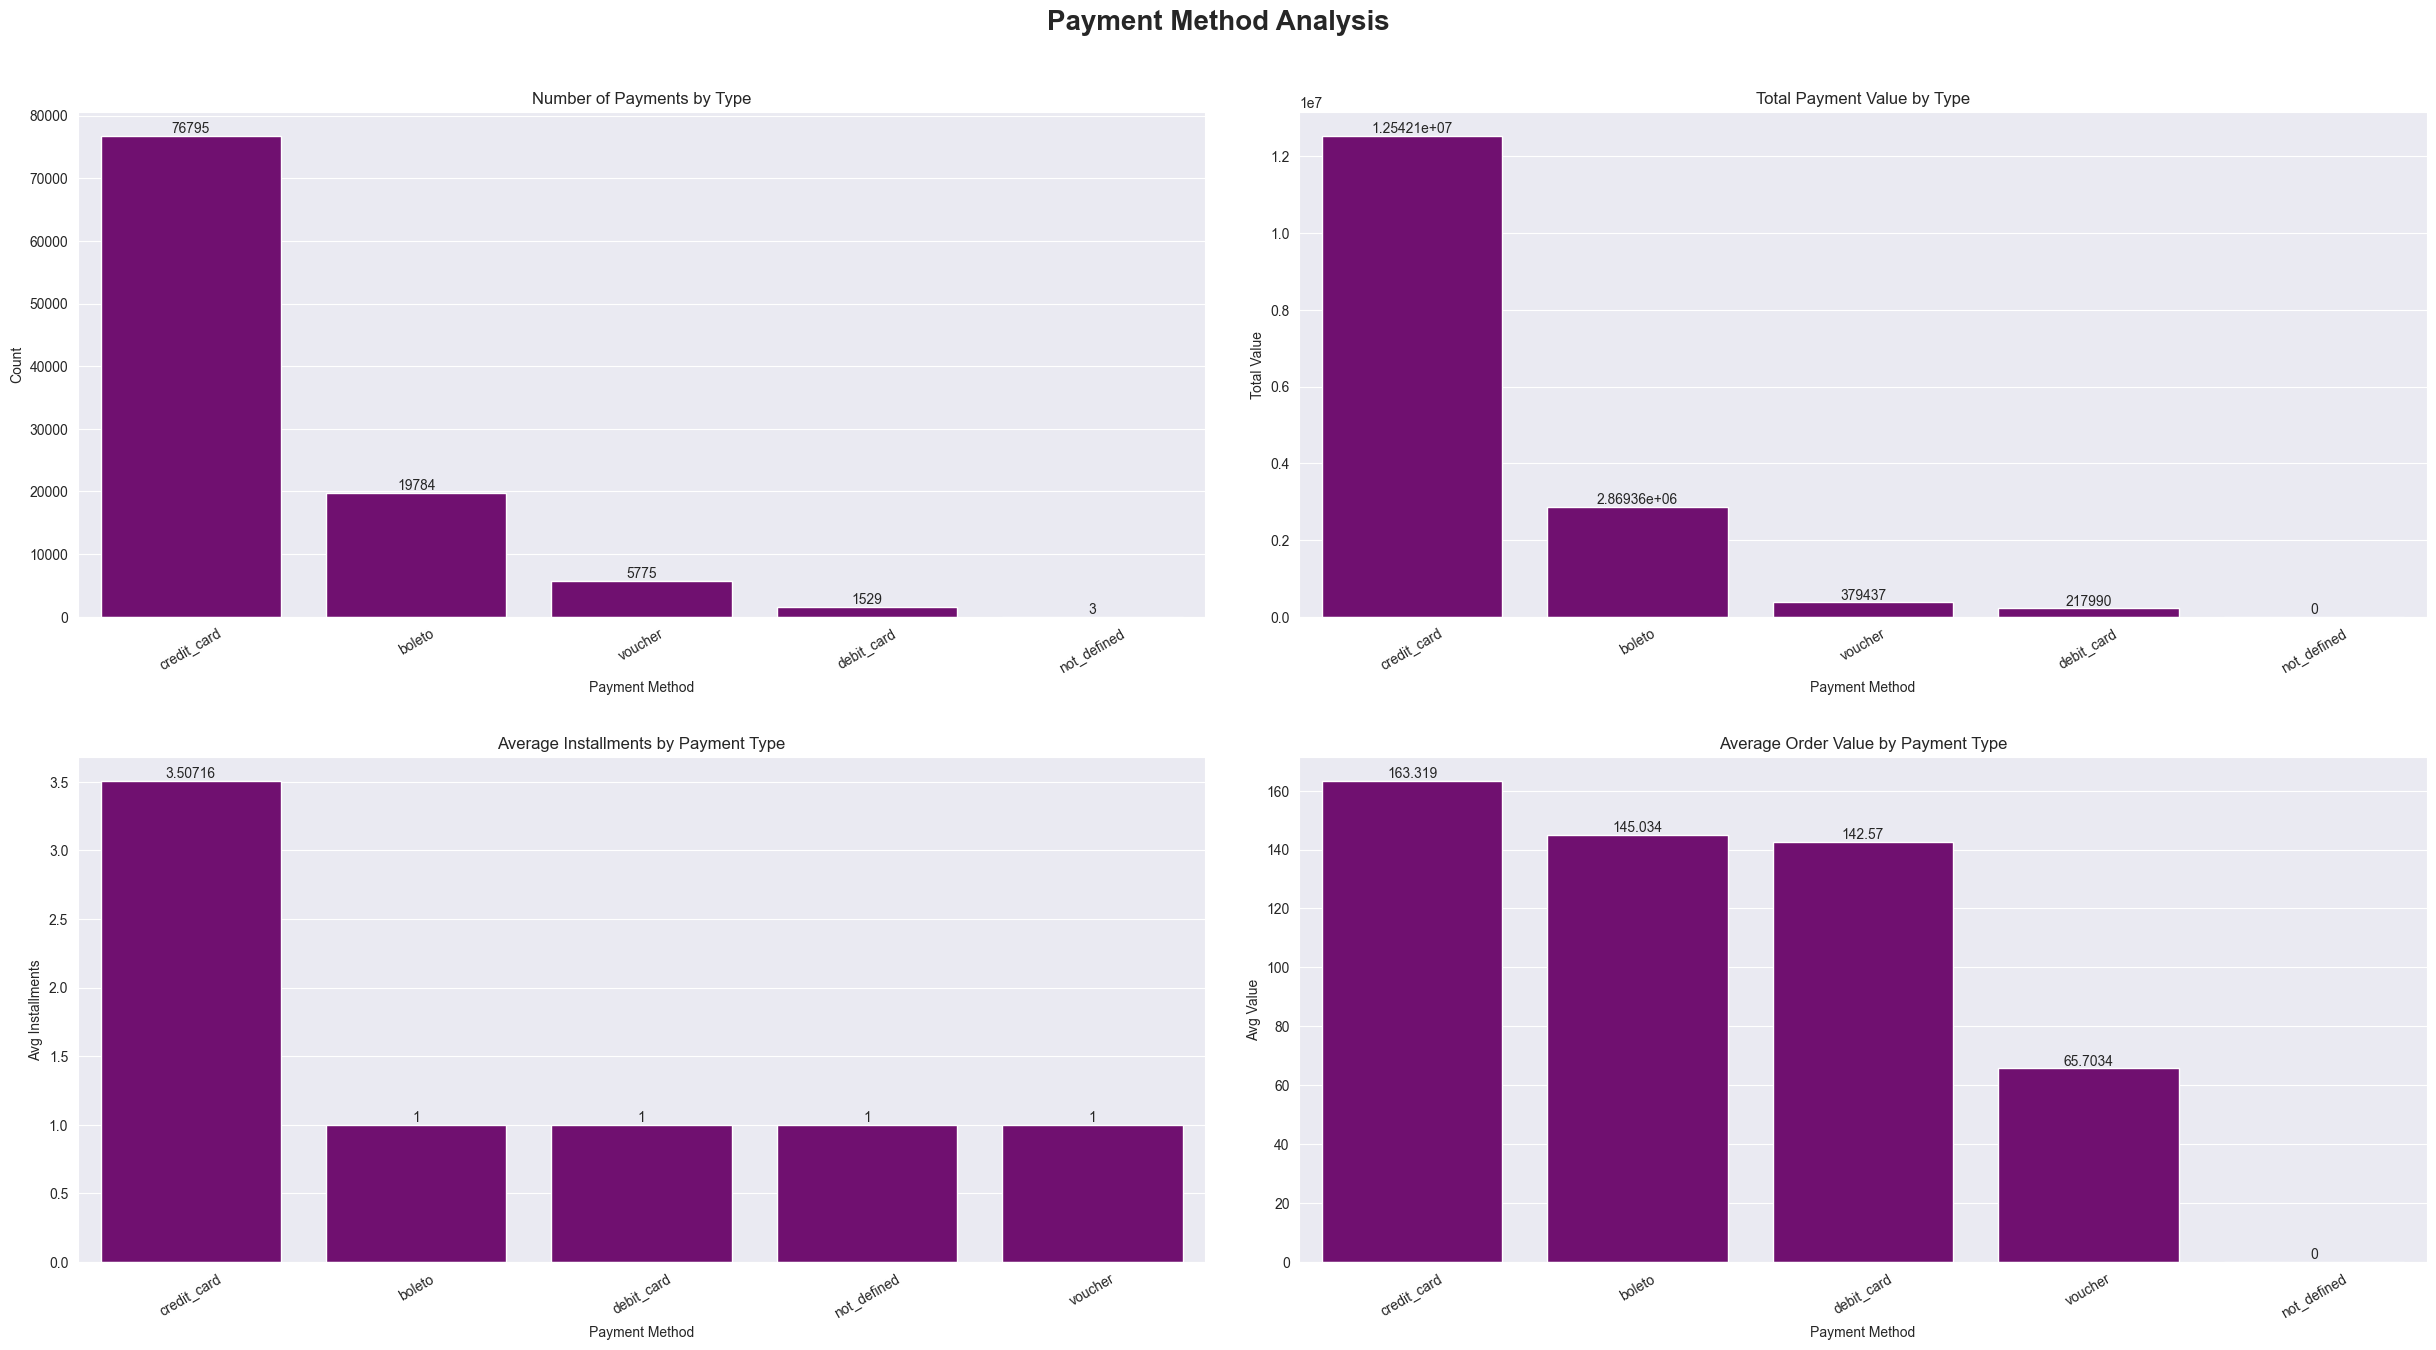

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(25,14))
sns.countplot(data=df, x='payment_type', color='purple', ax=axes[0,0])
axes[0,0].bar_label(axes[0,0].containers[0])
axes[0,0].set_title("Number of Payments by Type")
axes[0,0].set_xlabel("Payment Method")
axes[0,0].set_ylabel("Count")
axes[0,0].tick_params(axis='x', rotation=30)


sns.barplot(data=x4, x='Payment Method', y='payment value',color='purple', ax=axes[0,1])
axes[0,1].bar_label(axes[0,1].containers[0])
axes[0,1].set_title("Total Payment Value by Type")
axes[0,1].set_xlabel("Payment Method")
axes[0,1].set_ylabel("Total Value")
axes[0,1].tick_params(axis='x', rotation=30)


sns.barplot(data=x5, x='Payment Method', y='payment installments',color='purple',ax=axes[1,0])
axes[1,0].bar_label(axes[1,0].containers[0])
axes[1,0].set_title("Average Installments by Payment Type")
axes[1,0].set_xlabel("Payment Method")
axes[1,0].set_ylabel("Avg Installments")
axes[1,0].tick_params(axis='x', rotation=30)


sns.barplot(data=x6, x='Payment Method', y='payment value', color='purple',ax=axes[1,1])
axes[1,1].bar_label(axes[1,1].containers[0])
axes[1,1].set_title("Average Order Value by Payment Type")
axes[1,1].set_xlabel("Payment Method")
axes[1,1].set_ylabel("Avg Value")
axes[1,1].tick_params(axis='x', rotation=30)

plt.suptitle("Payment Method Analysis", fontsize=20, fontweight='bold')
plt.tight_layout(pad=3)
plt.savefig('Order_payment_paym_analysis.png', dpi=500, bbox_inches="tight")
plt.show()


<Axes: xlabel='payment_installments', ylabel='payment_value'>

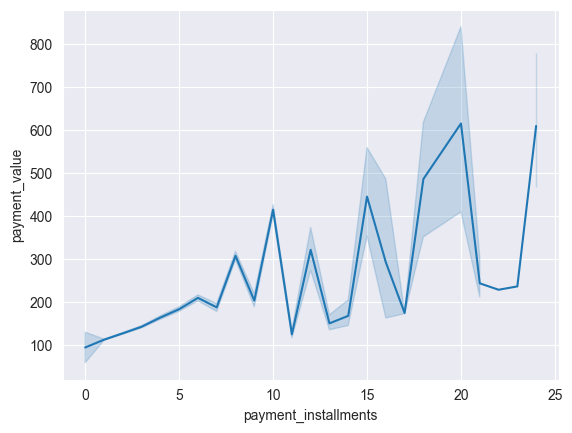

In [85]:
sns.lineplot(x=df['payment_installments'],y=df['payment_value'])

<Axes: xlabel='payment_sequential', ylabel='payment_value'>

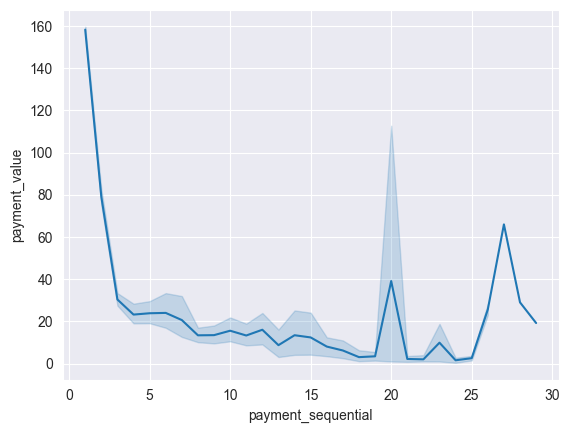

In [86]:
sns.lineplot(x=df['payment_sequential'],y=df['payment_value'])

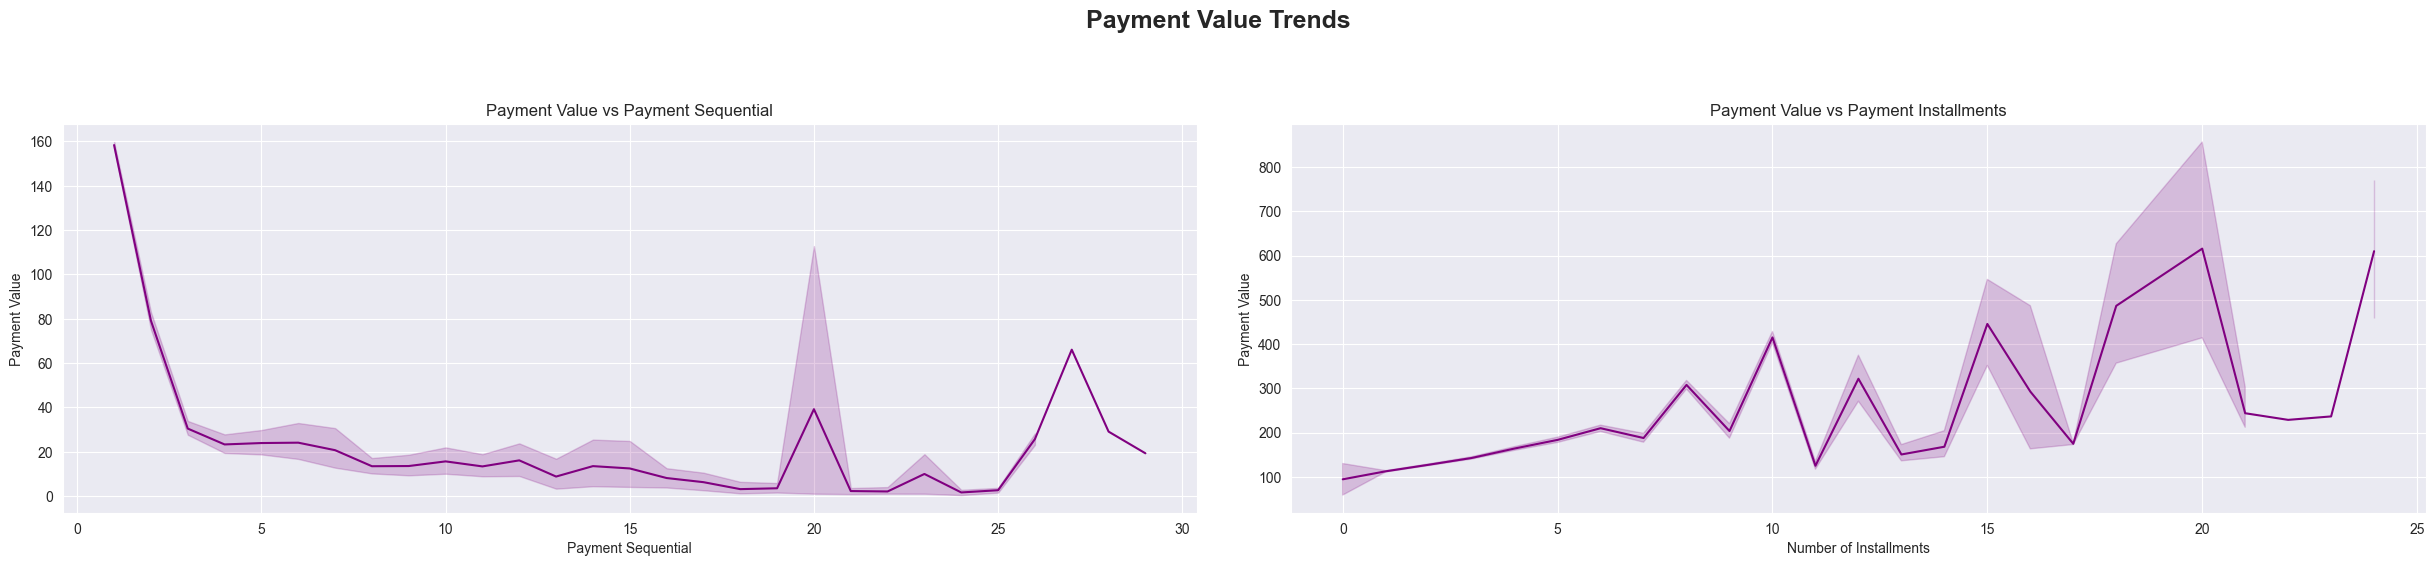

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(25,6))
sns.lineplot(x=df['payment_sequential'], y=df['payment_value'], color='purple', ax=axes[0])
axes[0].set_title("Payment Value vs Payment Sequential")
axes[0].set_xlabel("Payment Sequential")
axes[0].set_ylabel("Payment Value")

sns.lineplot(x=df['payment_installments'], y=df['payment_value'], color='purple', ax=axes[1])
axes[1].set_title("Payment Value vs Payment Installments")
axes[1].set_xlabel("Number of Installments")
axes[1].set_ylabel("Payment Value")

plt.suptitle("Payment Value Trends", fontsize=18, fontweight='bold')
plt.tight_layout(pad=3)
plt.savefig('Order_payment_price_trend.png', dpi=500, bbox_inches="tight")
plt.show()